In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

['Getting started.pdf',
 'IMG-20200909-WA0000 (1).jpg',
 'IMG-20200909-WA0000.jpg',
 'IMG-20200909-WA0001.jpg',
 'C3Uwi9aMmzxGPncblayh.pdf',
 'Document from Atharva 8-).pdf',
 'Bio print.pdf',
 'IMG-20210529-WA0006.jpg',
 'IMG_20210503_103916.jpg',
 'IMG_20210426_205852.jpg',
 '825b6740-ed00-41a0-815b-5be5ffc5fd94IMG_20211123_194744_3825484933128389604.jpg',
 '🗿',
 'CamScanner 02-17-2024 12.17.pdf',
 'image001 (1).png',
 'image001.png',
 'IMG-20240828-WA0025.jpg',
 'attendance excel.gsheet',
 'Colab Notebooks',
 'aptos2019-blindness-detection.zip',
 'aptos2019-blindness-detection 3']

In [ ]:
import os

APTOS_PATH = "/content/drive/MyDrive/aptos2019-blindness-detection 3"

print(os.listdir(APTOS_PATH))

['train_images', 'test_images', 'test.csv', 'train.csv', 'sample_submission.csv']


In [ ]:
import pandas as pd

APTOS_PATH = "/content/drive/MyDrive/aptos2019-blindness-detection 3"

train_df = pd.read_csv(f"{APTOS_PATH}/train.csv")

print(train_df.head())
print("\nDataset shape:", train_df.shape)

print("\nClass distribution:")
print(train_df["diagnosis"].value_counts().sort_index())

        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0

Dataset shape: (3662, 2)

Class distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


Image ID: 000c1434d8d7
Diagnosis: 2
Path: /content/drive/MyDrive/aptos2019-blindness-detection 3/train_images/000c1434d8d7.png
Exists: True


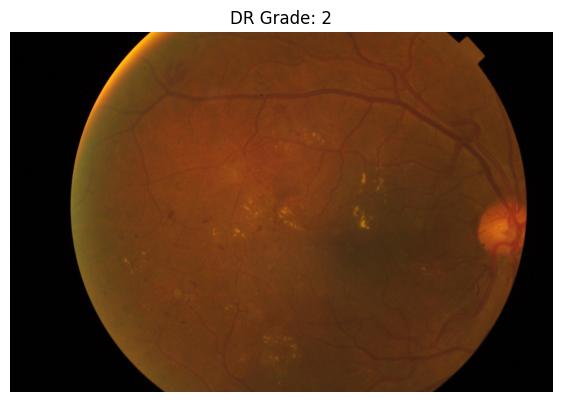

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

image_id = train_df.iloc[0]["id_code"]
label = train_df.iloc[0]["diagnosis"]

image_path = f"{APTOS_PATH}/train_images/{image_id}.png"

print("Image ID:", image_id)
print("Diagnosis:", label)
print("Path:", image_path)
print("Exists:", os.path.exists(image_path))

img = Image.open(image_path)

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.axis("off")
plt.title(f"DR Grade: {label}")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# First: 80% train, 20% temporary
train_df, temp_df = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["diagnosis"],
    random_state=42
)

# Then: split the temporary 20% into 10% validation + 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["diagnosis"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 2929
Validation: 366
Test: 367


In [ ]:
import torch
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class APTOSDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        image_id = self.dataframe.loc[idx, "id_code"]
        label = self.dataframe.loc[idx, "diagnosis"]

        image_path = os.path.join(
            self.image_dir,
            image_id + ".png"
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [ ]:
train_dataset = APTOSDataset(
    train_df,
    f"{APTOS_PATH}/train_images",
    train_transform
)

val_dataset = APTOSDataset(
    val_df,
    f"{APTOS_PATH}/train_images",
    val_test_transform
)

test_dataset = APTOSDataset(
    test_df,
    f"{APTOS_PATH}/train_images",
    val_test_transform
)

print(len(train_dataset))
print(len(val_dataset))
print(len(test_dataset))

2929
366
367


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully")

DataLoaders created successfully


In [ ]:
import timm
import torch.nn as nn

device = torch.device("cuda")

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

print("Model:", next(model.parameters()).device)

Model: cuda:0


In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([4, 0, 0, 2, 2, 0, 1, 1, 0, 0])


In [ ]:
import torch
import torch.nn as nn
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

print("Model loaded successfully")

Device: cuda
Model loaded successfully


In [ ]:
import torch

print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

True
Tesla T4


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Training setup ready")

Training setup ready


In [ ]:
from tqdm import tqdm

num_epochs = 10

for epoch in range(num_epochs):

    # Training
    model.train()
    train_loss = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

    for images, labels in progress_bar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    # Validation
    model.eval()
    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"\nEpoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Val Loss = {val_loss:.4f}, "
        f"Val Accuracy = {val_accuracy:.2f}%"
    )

Epoch 1/10: 100%|██████████| 92/92 [20:30<00:00, 13.37s/it, loss=0.746]



Epoch 1: Train Loss = 1.2794, Val Loss = 0.9286, Val Accuracy = 71.86%


Epoch 2/10: 100%|██████████| 92/92 [06:13<00:00,  4.06s/it, loss=0.486]



Epoch 2: Train Loss = 0.5964, Val Loss = 0.7654, Val Accuracy = 75.96%


Epoch 3/10: 100%|██████████| 92/92 [06:09<00:00,  4.01s/it, loss=0.361]



Epoch 3: Train Loss = 0.4325, Val Loss = 0.7390, Val Accuracy = 76.23%


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 92/92 [06:07<00:00,  4.00s/it, loss=0.212]



Epoch 9: Train Loss = 0.1317, Val Loss = 0.8244, Val Accuracy = 79.23%


Epoch 10/10: 100%|██████████| 92/92 [06:13<00:00,  4.06s/it, loss=0.0571]



Epoch 10: Train Loss = 0.1081, Val Loss = 0.9738, Val Accuracy = 78.69%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

               precision    recall  f1-score   support

        No DR     0.9725    0.9779    0.9752       181
         Mild     0.5455    0.3243    0.4068        37
     Moderate     0.7008    0.8900    0.7841       100
       Severe     0.5556    0.2632    0.3571        19
Proliferative     0.5556    0.5000    0.5263        30

     accuracy                         0.8120       367
    macro avg     0.6660    0.5911    0.6099       367
 weighted avg     0.7998    0.8120    0.7971       367

Confusion Matrix:
[[177   3   1   0   0]
 [  5  12  19   1   0]
 [  0   4  89   2   5]
 [  0   1   6   5   7]
 [  0   2  12   1  15]]


In [ ]:
import numpy as np
import torch

class_counts = train_df["diagnosis"].value_counts().sort_index().values

class_weights = len(train_df) / (5 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: [1444  296  799  154  236]
Class weights: tensor([0.4057, 1.9791, 0.7332, 3.8039, 2.4822], device='cuda:0')


In [ ]:
model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("New model ready")

New model ready


In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    model.train()
    train_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs}"
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        progress_bar.set_postfix(loss=loss.item())

    model.eval()

    val_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            total += labels.size(0)
            correct += (predictions == labels).sum().item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    val_accuracy = 100 * correct / total

    print(
        f"Epoch {epoch+1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Val Loss = {val_loss:.4f}, "
        f"Val Accuracy = {val_accuracy:.2f}%"
    )

Epoch 1/10: 100%|██████████| 92/92 [06:14<00:00,  4.07s/it, loss=0.987]


Epoch 1: Train Loss = 2.0252, Val Loss = 1.5130, Val Accuracy = 60.93%


Epoch 2/10: 100%|██████████| 92/92 [06:16<00:00,  4.09s/it, loss=0.509]


Epoch 2: Train Loss = 0.9854, Val Loss = 1.4914, Val Accuracy = 66.39%


Epoch 3/10: 100%|██████████| 92/92 [06:13<00:00,  4.06s/it, loss=1.14]


Epoch 3: Train Loss = 0.7339, Val Loss = 1.3436, Val Accuracy = 67.76%


... (10 outputs left out)

Epoch 9/10: 100%|██████████| 92/92 [06:08<00:00,  4.01s/it, loss=0.569]


Epoch 9: Train Loss = 0.2266, Val Loss = 1.4810, Val Accuracy = 76.23%


Epoch 10/10: 100%|██████████| 92/92 [06:10<00:00,  4.03s/it, loss=0.449]


Epoch 10: Train Loss = 0.2120, Val Loss = 1.5632, Val Accuracy = 77.05%


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

               precision    recall  f1-score   support

        No DR     0.9774    0.9558    0.9665       181
         Mild     0.6296    0.4595    0.5312        37
     Moderate     0.7476    0.7700    0.7586       100
       Severe     0.3871    0.6316    0.4800        19
Proliferative     0.5517    0.5333    0.5424        30

     accuracy                         0.8038       367
    macro avg     0.6587    0.6700    0.6557       367
 weighted avg     0.8144    0.8038    0.8061       367

Confusion Matrix:
[[173   4   4   0   0]
 [  4  17  14   1   1]
 [  0   3  77  11   9]
 [  0   1   3  12   3]
 [  0   2   5   7  16]]


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Convert 5-class predictions into referable / non-referable
binary_labels = [1 if x >= 2 else 0 for x in all_labels]
binary_preds = [1 if x >= 2 else 0 for x in all_preds]

print(classification_report(
    binary_labels,
    binary_preds,
    target_names=["Non-Referable", "Referable"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(binary_labels, binary_preds))

               precision    recall  f1-score   support

Non-Referable     0.9706    0.9083    0.9384       218
    Referable     0.8773    0.9597    0.9167       149

     accuracy                         0.9292       367
    macro avg     0.9239    0.9340    0.9275       367
 weighted avg     0.9327    0.9292    0.9296       367

Confusion Matrix:
[[198  20]
 [  6 143]]


In [ ]:
torch.save(
    model.state_dict(),
    "/content/drive/MyDrive/SIH26038_efficientnet_b0_weighted.pth"
)

print("Model saved successfully")

Model saved successfully


In [ ]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

print("Grad-CAM ready")

Grad-CAM ready


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Pick one test image
sample = test_df.iloc[0]

image_id = sample["id_code"]
true_label = sample["diagnosis"]

image_path = f"{APTOS_PATH}/train_images/{image_id}.png"

# Load original image
original_image = Image.open(image_path).convert("RGB")

# Preprocess
input_tensor = val_test_transform(original_image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    output = model(input_tensor)
    predicted_class = torch.argmax(output, dim=1).item()

print("Image:", image_id)
print("True class:", true_label)
print("Predicted class:", predicted_class)

Image: 3580a545016d
True class: 0
Predicted class: 0


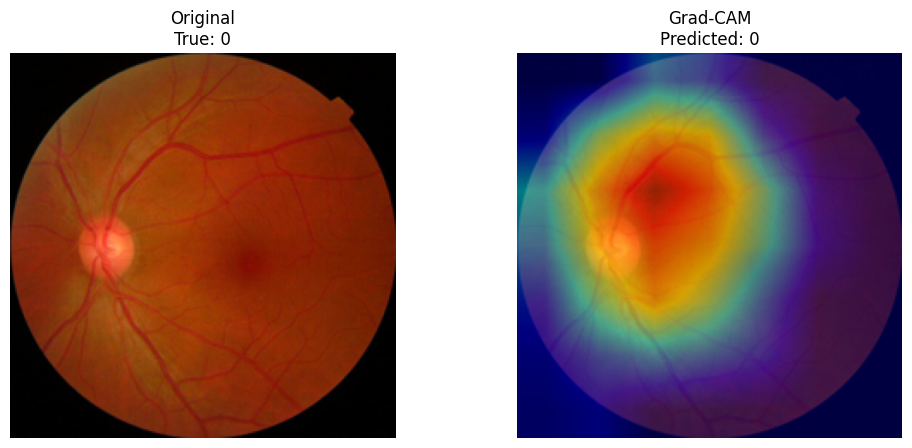

In [ ]:
# Resize original image to match model input
rgb_img = np.array(
    original_image.resize((224, 224))
).astype(np.float32) / 255.0

visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_img)
plt.title(f"Original\nTrue: {true_label}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(f"Grad-CAM\nPredicted: {predicted_class}")
plt.axis("off")

plt.show()

In [ ]:
import torch.nn.functional as F

def predict_with_gradcam(image_path):

    original = Image.open(image_path).convert("RGB")

    input_tensor = val_test_transform(original).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = F.softmax(output, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()
        confidence = probabilities[0][predicted_class].item()

    targets = [ClassifierOutputTarget(predicted_class)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    rgb_img = np.array(
        original.resize((224, 224))
    ).astype(np.float32) / 255.0

    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )

    print("Predicted DR Grade:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(rgb_img)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title(f"Grad-CAM — Grade {predicted_class}")
    plt.axis("off")

    plt.show()

Predicted DR Grade: 0
Confidence: 96.55%


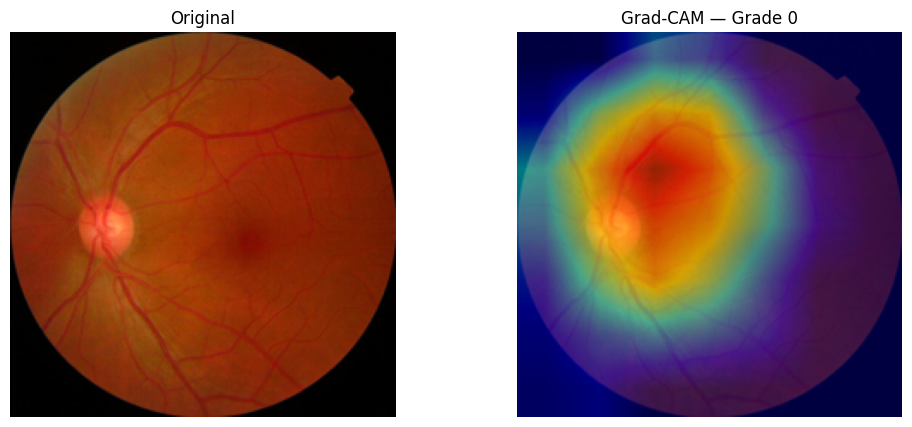

In [ ]:
predict_with_gradcam(
    f"{APTOS_PATH}/train_images/{test_df.iloc[0]['id_code']}.png"
)


===== TRUE GRADE: 0 =====
Predicted DR Grade: 0
Confidence: 96.55%


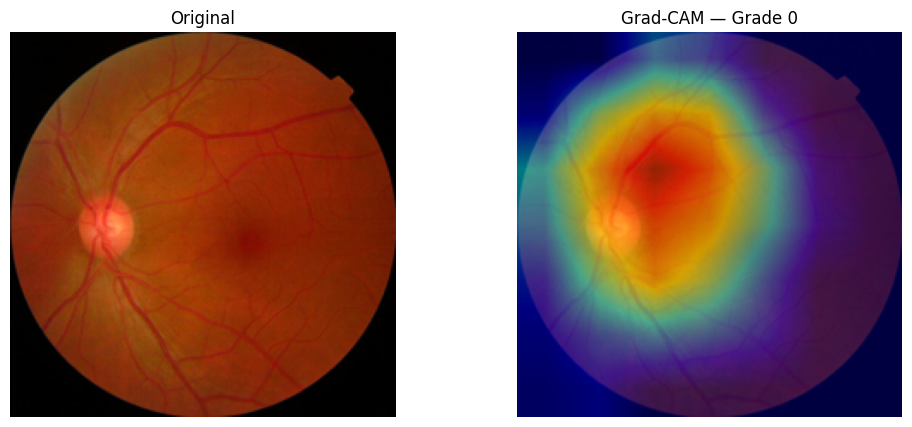


===== TRUE GRADE: 1 =====
Predicted DR Grade: 2
Confidence: 63.93%


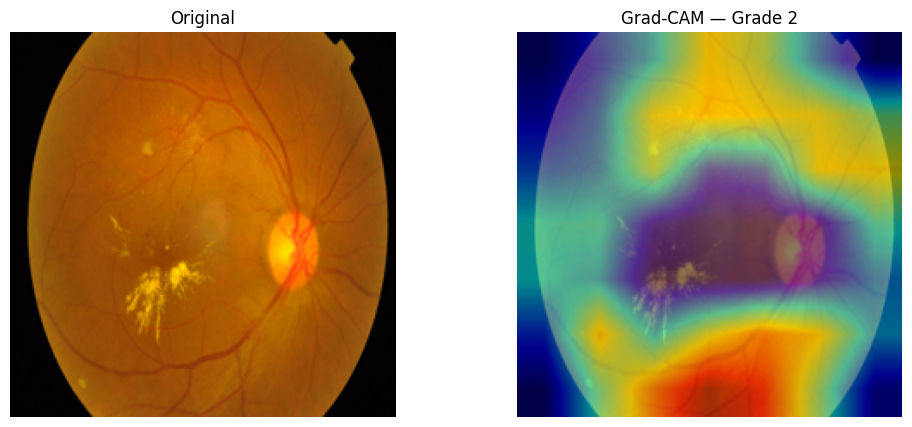


===== TRUE GRADE: 2 =====
Predicted DR Grade: 2
Confidence: 75.26%


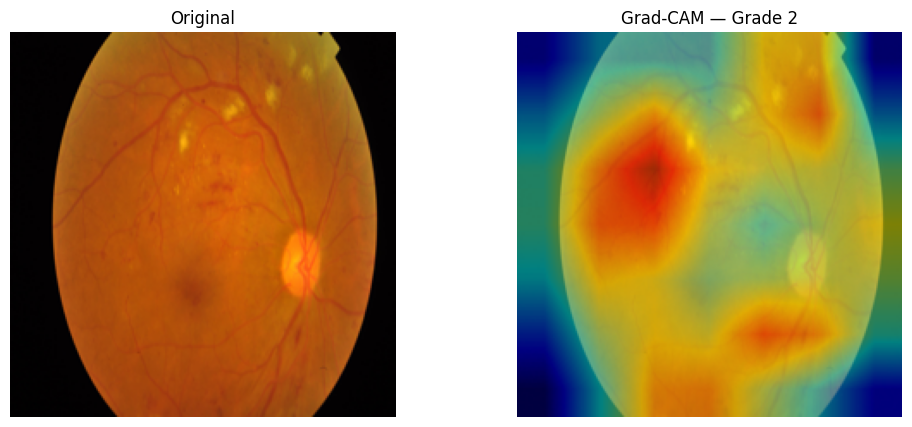


===== TRUE GRADE: 3 =====
Predicted DR Grade: 3
Confidence: 49.44%


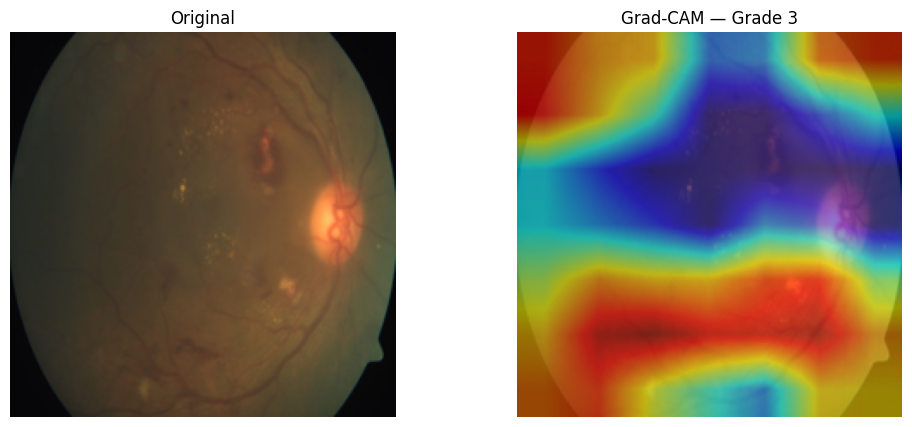


===== TRUE GRADE: 4 =====
Predicted DR Grade: 4
Confidence: 79.92%


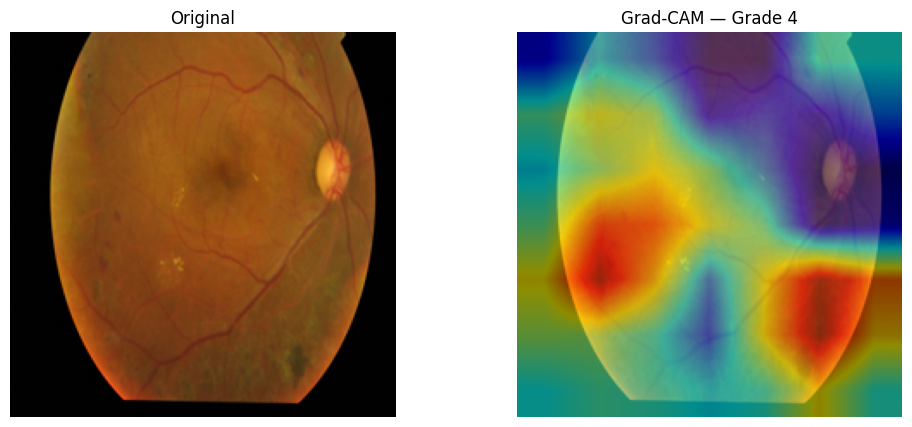

In [ ]:
for grade in range(5):

    sample = test_df[test_df["diagnosis"] == grade].iloc[0]

    image_path = (
        f"{APTOS_PATH}/train_images/"
        f"{sample['id_code']}.png"
    )

    print(f"\n===== TRUE GRADE: {grade} =====")

    predict_with_gradcam(image_path)

In [ ]:
torch.save(
    model,
    "/content/drive/MyDrive/SIH26038_final_model.pth"
)

print("Final model saved.")

Final model saved.


In [ ]:
import cv2
import numpy as np

def check_image_quality(image_path):

    img = cv2.imread(image_path)

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Blur score
    blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()

    # Brightness
    brightness = np.mean(gray)

    # Contrast
    contrast = np.std(gray)

    print(f"Blur score: {blur_score:.2f}")
    print(f"Brightness: {brightness:.2f}")
    print(f"Contrast: {contrast:.2f}")

    return blur_score, brightness, contrast

In [ ]:
sample_path = (
    f"{APTOS_PATH}/train_images/"
    f"{test_df.iloc[0]['id_code']}.png"
)

check_image_quality(sample_path)

Blur score: 50.89
Brightness: 58.48
Contrast: 32.52


(np.float64(50.89224475972789),
 np.float64(58.47562993197279),
 np.float64(32.52240588514069))

In [ ]:
quality_results = []

for _, row in test_df.iterrows():

    image_path = (
        f"{APTOS_PATH}/train_images/"
        f"{row['id_code']}.png"
    )

    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    blur = cv2.Laplacian(gray, cv2.CV_64F).var()
    brightness = np.mean(gray)
    contrast = np.std(gray)

    quality_results.append([
        row["id_code"],
        row["diagnosis"],
        blur,
        brightness,
        contrast
    ])

quality_df = pd.DataFrame(
    quality_results,
    columns=[
        "id_code",
        "diagnosis",
        "blur",
        "brightness",
        "contrast"
    ]
)

print(quality_df.describe())

        diagnosis        blur  brightness    contrast
count  367.000000  367.000000  367.000000  367.000000
mean     1.128065   23.981261   67.728425   40.014530
std      1.302563   18.878542   18.552364    9.429011
min      0.000000    2.992568   14.966184   14.983101
25%      0.000000    9.206115   52.115990   32.855909
50%      1.000000   16.218405   71.296790   41.610395
75%      2.000000   42.989038   81.523626   45.880135
max      4.000000  130.135144  129.618188   63.627925


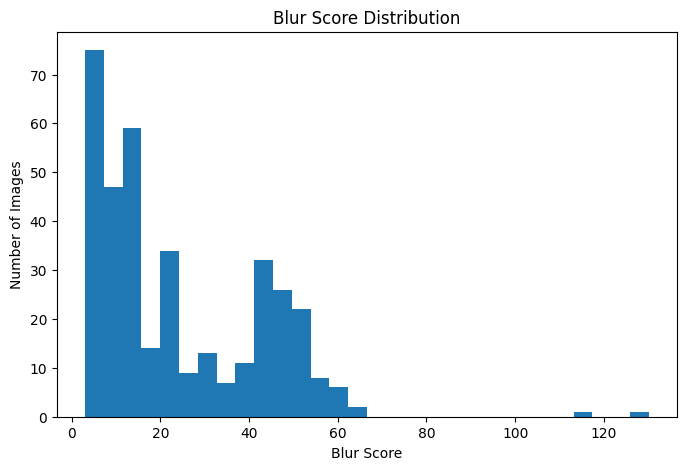

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(quality_df["blur"], bins=30)
plt.xlabel("Blur Score")
plt.ylabel("Number of Images")
plt.title("Blur Score Distribution")
plt.show()

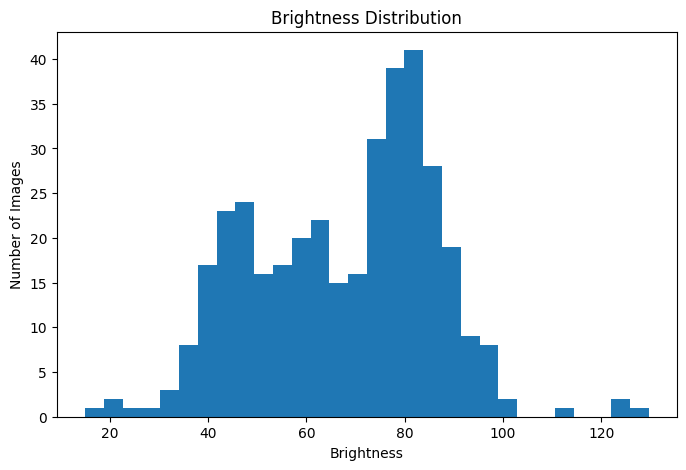

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(quality_df["brightness"], bins=30)
plt.xlabel("Brightness")
plt.ylabel("Number of Images")
plt.title("Brightness Distribution")
plt.show()

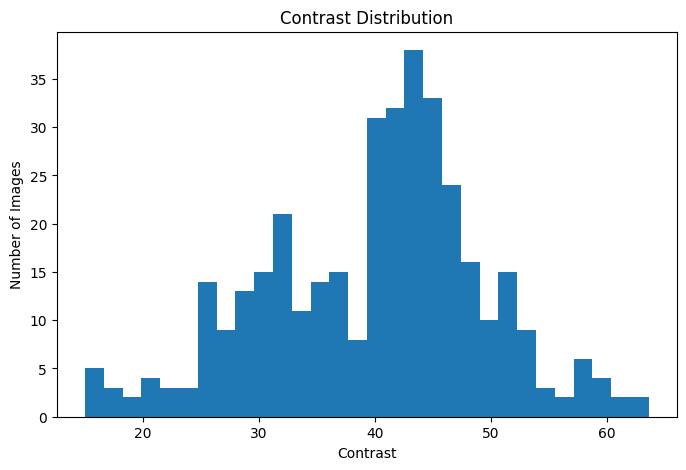

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(quality_df["contrast"], bins=30)
plt.xlabel("Contrast")
plt.ylabel("Number of Images")
plt.title("Contrast Distribution")
plt.show()

In [ ]:
import torch.nn.functional as F

def final_prediction(image_path):

    original = Image.open(image_path).convert("RGB")

    # Preprocess
    input_tensor = val_test_transform(original).unsqueeze(0).to(device)

    # Prediction
    model.eval()

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = F.softmax(output, dim=1)

    predicted_class = torch.argmax(probabilities, dim=1).item()
    confidence = probabilities[0][predicted_class].item()

    # Referable DR: Grade 2, 3, 4
    referable = predicted_class >= 2

    # Grad-CAM
    targets = [ClassifierOutputTarget(predicted_class)]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    rgb_img = np.array(
        original.resize((224, 224))
    ).astype(np.float32) / 255.0

    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )

    grade_names = {
        0: "No DR",
        1: "Mild DR",
        2: "Moderate DR",
        3: "Severe DR",
        4: "Proliferative DR"
    }

    print("================================")
    print("DIABETIC RETINOPATHY SCREENING")
    print("================================")
    print(f"DR Grade: {predicted_class}")
    print(f"Classification: {grade_names[predicted_class]}")
    print(f"Confidence: {confidence * 100:.2f}%")
    print(
        "Referral Status:",
        "REFER" if referable else "NOT REFER"
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(rgb_img)
    plt.title("Fundus Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title("Grad-CAM Explanation")
    plt.axis("off")

    plt.show()

DIABETIC RETINOPATHY SCREENING
DR Grade: 0
Classification: No DR
Confidence: 99.96%
Referral Status: NOT REFER


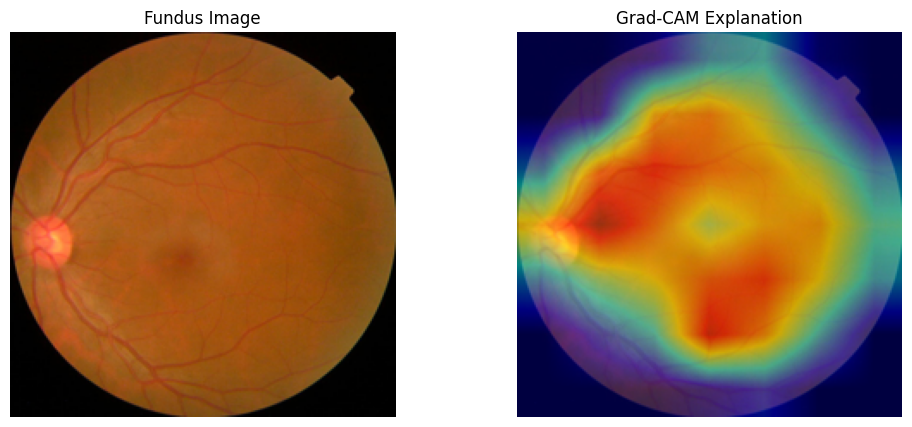

In [ ]:
final_prediction(
    f"{APTOS_PATH}/train_images/{test_df.iloc[10]['id_code']}.png"
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Colab Notebooks', 'Getting started.pdf', 'IMG-20200909-WA0000 (1).jpg', 'IMG-20200909-WA0000.jpg', 'IMG-20200909-WA0001.jpg', 'C3Uwi9aMmzxGPncblayh.pdf', 'Document from Atharva 8-).pdf', 'Bio print.pdf', 'IMG-20210529-WA0006.jpg', 'IMG_20210503_103916.jpg', 'IMG_20210426_205852.jpg', '825b6740-ed00-41a0-815b-5be5ffc5fd94IMG_20211123_194744_3825484933128389604.jpg', '🗿', 'CamScanner 02-17-2024 12.17.pdf', 'image001 (1).png', 'image001.png', 'IMG-20240828-WA0025.jpg', 'attendance excel.gsheet', 'aptos2019-blindness-detection.zip', 'SIH26038_efficientnet_b0_weighted.pth', 'SIH26038_final_model.pth', 'SIH26038']


In [ ]:
import os

SIH_PATH = "/content/drive/MyDrive/SIH26038"

print(os.listdir(SIH_PATH))

['aptos2019-blindness-detection 3', 'IDRiD']


In [ ]:
import os

IDRID_PATH = "/content/drive/MyDrive/SIH26038/IDRiD"

print(os.listdir(IDRID_PATH))

['C. Localization.zip', 'B. Disease Grading.zip', 'A. Segmentation.zip']


In [ ]:
import zipfile
import os

seg_zip = "/content/drive/MyDrive/SIH26038/IDRiD/A. Segmentation.zip"
extract_path = "/content/IDRiD_Segmentation"

with zipfile.ZipFile(seg_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(os.listdir(extract_path))

['A. Segmentation']


In [ ]:
seg_path = "/content/IDRiD_Segmentation/A. Segmentation"

print(os.listdir(seg_path))

['2. All Segmentation Groundtruths', '1. Original Images', 'LICENSE.txt', 'CC-BY-4.0.txt']


In [ ]:
gt_path = "/content/IDRiD_Segmentation/A. Segmentation/2. All Segmentation Groundtruths"

print(os.listdir(gt_path))

['a. Training Set', 'b. Testing Set']


In [ ]:
train_gt_path = "/content/IDRiD_Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set"

print(os.listdir(train_gt_path))

['1. Microaneurysms', '2. Haemorrhages', '3. Hard Exudates', '5. Optic Disc', '4. Soft Exudates']


In [ ]:
import os

for folder in os.listdir(train_gt_path):
    folder_path = os.path.join(train_gt_path, folder)
    files = os.listdir(folder_path)
    print(folder, "→", len(files), "files")

1. Microaneurysms → 54 files
2. Haemorrhages → 53 files
3. Hard Exudates → 54 files
5. Optic Disc → 54 files
4. Soft Exudates → 26 files


In [ ]:
from PIL import Image
import os

ma_path = os.path.join(
    train_gt_path,
    "1. Microaneurysms"
)

sample_file = os.listdir(ma_path)[0]
sample_path = os.path.join(ma_path, sample_file)

img = Image.open(sample_path)

print("File:", sample_file)
print("Size:", img.size)
print("Mode:", img.mode)

File: IDRiD_28_MA.tif
Size: (4288, 2848)
Mode: P


In [ ]:
import matplotlib.pyplot as plt

original_path = "/content/IDRiD_Segmentation/A. Segmentation/1. Original Images/IDRiD_28.jpg"

original = Image.open(original_path)
mask = Image.open(sample_path)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Microaneurysm Mask")
plt.axis("off")

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/content/IDRiD_Segmentation/A. Segmentation/1. Original Images/IDRiD_28.jpg'

In [ ]:
original_path = "/content/IDRiD_Segmentation/A. Segmentation/1. Original Images"

print(os.listdir(original_path)[:10])

['a. Training Set', 'b. Testing Set']


In [ ]:
import os

IDRID_BASE = "/content/drive/MyDrive/SIH26038/IDRiD"

for root, dirs, files in os.walk(IDRID_BASE):
    level = root.replace(IDRID_BASE, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for file in files[:5]:
            print("  " * (level + 1) + file)

IDRiD/
  C. Localization.zip
  B. Disease Grading.zip
  A. Segmentation.zip
  B. Disease Grading/
    CC-BY-4.0.txt
    LICENSE.txt
    1. Original Images/
      b. Testing Set/
        IDRiD_053.jpg
        IDRiD_087.jpg
        IDRiD_069.jpg
        IDRiD_025.jpg
        IDRiD_096.jpg
      a. Training Set/
        IDRiD_291.jpg
        IDRiD_078.jpg
        IDRiD_332.jpg
        IDRiD_130.jpg
        IDRiD_246.jpg
    2. Groundtruths/
      b. IDRiD_Disease Grading_Testing Labels.csv
      a. IDRiD_Disease Grading_Training Labels.csv
  C. Localization/
    CC-BY-4.0.txt
    LICENSE.txt
    1. Original Images/
      a. Training Set/
        IDRiD_118.jpg
        IDRiD_124.jpg
        IDRiD_130.jpg
        IDRiD_326.jpg
        IDRiD_127.jpg
      b. Testing Set/
        IDRiD_086.jpg
        IDRiD_050.jpg
        IDRiD_079.jpg
        IDRiD_084.jpg
        IDRiD_081.jpg
    2. Groundtruths/
      1. Optic Disc Center Location/
        b. IDRiD_OD_Center_Testing Set_Markups.csv
      

In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

IDRID_BASE = "/content/drive/MyDrive/SIH26038/IDRiD"

SEG_PATH = os.path.join(IDRID_BASE, "A. Segmentation")
IMG_PATH = os.path.join(SEG_PATH, "1. Original Images", "a. Training Set")
GT_PATH = os.path.join(SEG_PATH, "2. All Segmentation Groundtruths", "a. Training Set")

print("Images:", len(os.listdir(IMG_PATH)))
print("Groundtruth folders:", os.listdir(GT_PATH))

Images: 54
Groundtruth folders: ['3. Hard Exudates', '4. Soft Exudates', '5. Optic Disc', '2. Haemorrhages', '1. Microaneurysms']


In [ ]:
print("Original images:")
print(os.listdir(IMG_PATH)[:10])

print("\nMicroaneurysm masks:")
print(os.listdir(os.path.join(GT_PATH, "1. Microaneurysms"))[:10])

Original images:
['IDRiD_23.jpg', 'IDRiD_18.jpg', 'IDRiD_24.jpg', 'IDRiD_26.jpg', 'IDRiD_27.jpg', 'IDRiD_32.jpg', 'IDRiD_33.jpg', 'IDRiD_31.jpg', 'IDRiD_25.jpg', 'IDRiD_34.jpg']

Microaneurysm masks:
['IDRiD_02_MA.tif', 'IDRiD_10_MA.tif', 'IDRiD_49_MA.tif', 'IDRiD_34_MA.tif', 'IDRiD_45_MA.tif', 'IDRiD_26_MA.tif', 'IDRiD_38_MA.tif', 'IDRiD_24_MA.tif', 'IDRiD_12_MA.tif', 'IDRiD_36_MA.tif']


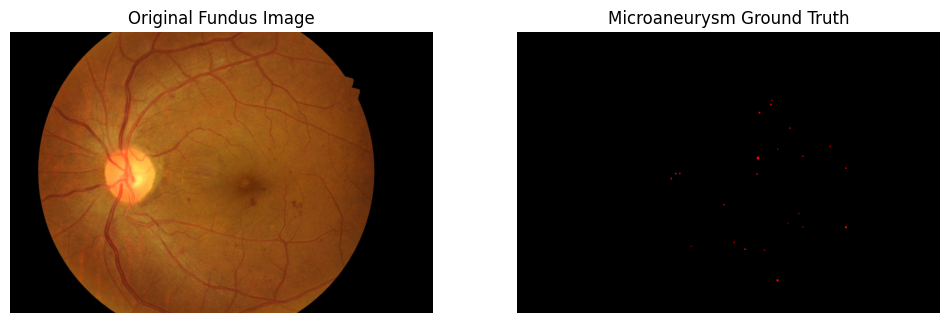

In [ ]:
image_file = "IDRiD_28.jpg"
mask_file = "IDRiD_28_MA.tif"

image = Image.open(os.path.join(IMG_PATH, image_file))
mask = Image.open(
    os.path.join(GT_PATH, "1. Microaneurysms", mask_file)
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Microaneurysm Ground Truth")
plt.axis("off")

plt.show()

Missing: /content/drive/MyDrive/SIH26038/IDRiD/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/4. Soft Exudates/IDRiD_28_SE.tif


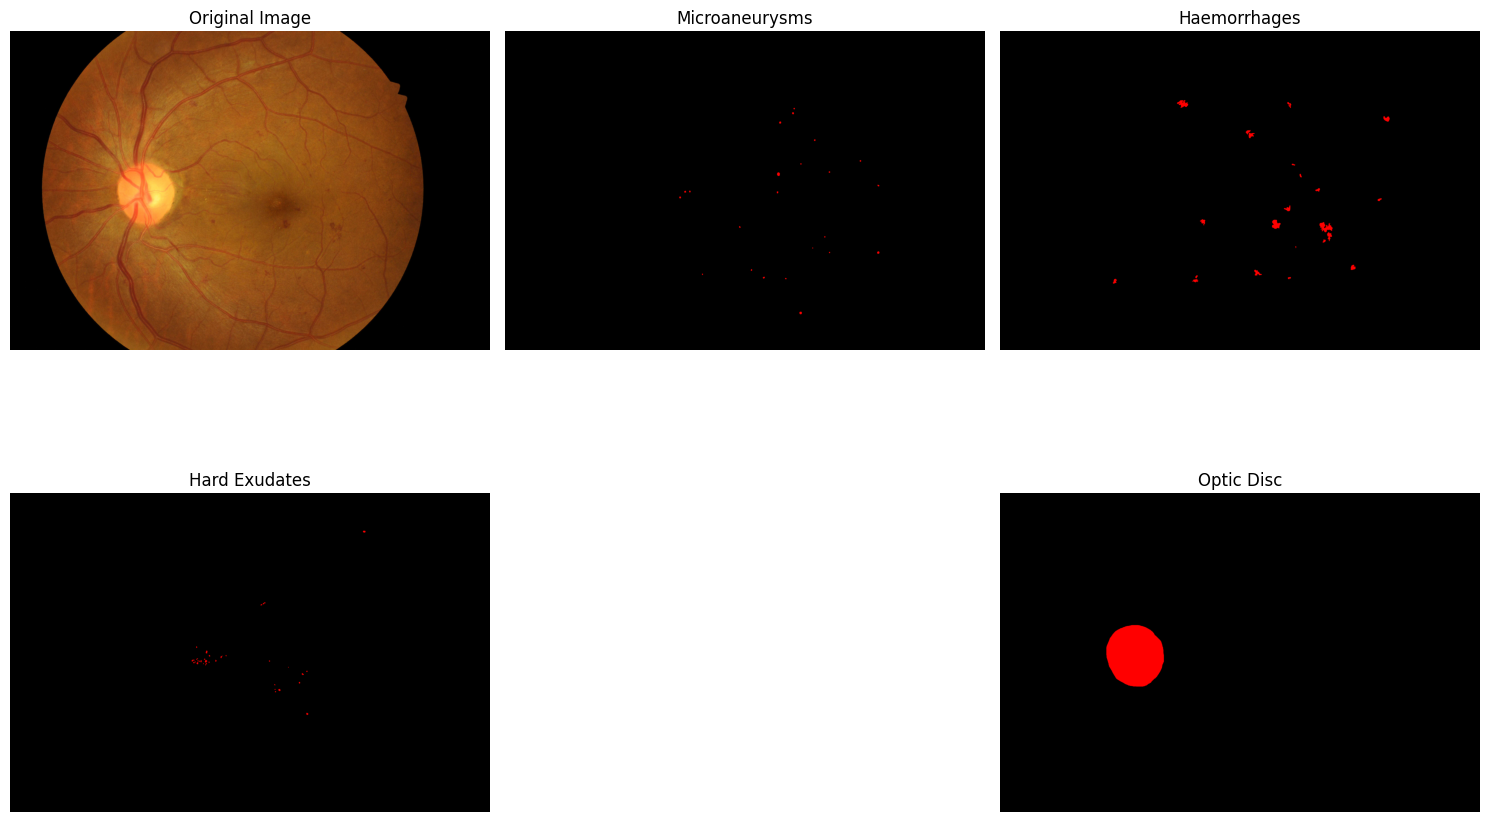

In [ ]:
lesions = {
    "Microaneurysms": "1. Microaneurysms",
    "Haemorrhages": "2. Haemorrhages",
    "Hard Exudates": "3. Hard Exudates",
    "Soft Exudates": "4. Soft Exudates",
    "Optic Disc": "5. Optic Disc"
}

image = Image.open(os.path.join(IMG_PATH, "IDRiD_28.jpg"))

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

for i, (name, folder) in enumerate(lesions.items(), start=2):

    if name == "Microaneurysms":
        suffix = "_MA.tif"
    elif name == "Haemorrhages":
        suffix = "_HE.tif"
    elif name == "Hard Exudates":
        suffix = "_EX.tif"
    elif name == "Soft Exudates":
        suffix = "_SE.tif"
    elif name == "Optic Disc":
        suffix = "_OD.tif"

    mask_path = os.path.join(
        GT_PATH,
        folder,
        "IDRiD_28" + suffix
    )

    if os.path.exists(mask_path):
        mask = Image.open(mask_path)

        plt.subplot(2, 3, i)
        plt.imshow(mask)
        plt.title(name)
        plt.axis("off")
    else:
        print("Missing:", mask_path)

plt.tight_layout()
plt.show()

In [ ]:
se_path = os.path.join(GT_PATH, "4. Soft Exudates")

se_files = os.listdir(se_path)

print("Number of Soft Exudate masks:", len(se_files))
print("First 10 files:")
print(se_files[:10])

Number of Soft Exudate masks: 26
First 10 files:
['IDRiD_08_SE.tif', 'IDRiD_32_SE.tif', 'IDRiD_51_SE.tif', 'IDRiD_14_SE.tif', 'IDRiD_18_SE.tif', 'IDRiD_53_SE.tif', 'IDRiD_30_SE.tif', 'IDRiD_38_SE.tif', 'IDRiD_22_SE.tif', 'IDRiD_49_SE.tif']


Image: IDRiD_08.jpg
Mask: IDRiD_08_SE.tif
Image size: (4288, 2848)
Mask size: (4288, 2848)


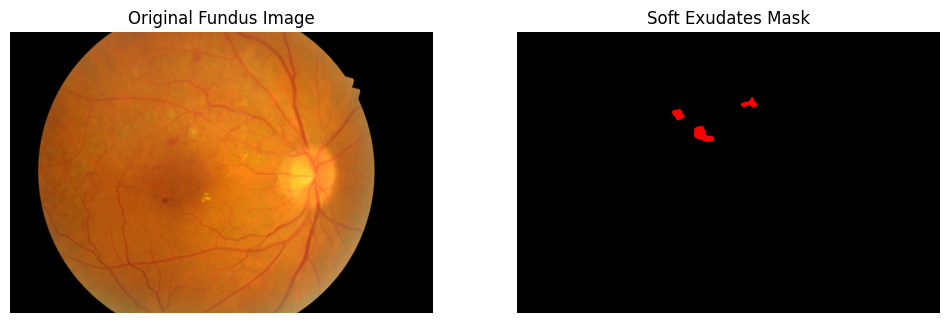

In [ ]:
# Pick the first available Soft Exudate mask
se_file = se_files[0]

# Get corresponding image name
image_name = se_file.replace("_SE.tif", ".jpg")

soft_mask = Image.open(os.path.join(se_path, se_file))
original = Image.open(os.path.join(IMG_PATH, image_name))

print("Image:", image_name)
print("Mask:", se_file)
print("Image size:", original.size)
print("Mask size:", soft_mask.size)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(soft_mask)
plt.title("Soft Exudates Mask")
plt.axis("off")

plt.show()

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
from PIL import Image
import os

class IDRiDSegmentationDataset(Dataset):

    def __init__(self, image_dir, mask_dir, image_size=(512, 512)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

        self.images = [
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        self.images.sort()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]
        image_path = os.path.join(self.image_dir, image_name)

        image = Image.open(image_path).convert("RGB")
        image = image.resize(self.image_size)

        image = np.array(image) / 255.0
        image = torch.tensor(image, dtype=torch.float32).permute(2, 0, 1)

        image_id = os.path.splitext(image_name)[0]

        masks = []

        lesion_info = {
            "MA": "1. Microaneurysms",
            "HE": "2. Haemorrhages",
            "EX": "3. Hard Exudates",
            "SE": "4. Soft Exudates"
        }

        for suffix, folder in lesion_info.items():

            mask_path = os.path.join(
                self.mask_dir,
                folder,
                image_id + "_" + suffix + ".tif"
            )

            if os.path.exists(mask_path):

                mask = Image.open(mask_path).convert("L")
                mask = mask.resize(self.image_size)

                mask = np.array(mask)

                # Convert mask to binary
                mask = (mask > 0).astype(np.float32)

            else:
                # No annotation available
                mask = np.zeros(self.image_size, dtype=np.float32)

            masks.append(mask)

        masks = np.stack(masks, axis=0)
        masks = torch.tensor(masks, dtype=torch.float32)

        return image, masks, image_name

In [ ]:
dataset = IDRiDSegmentationDataset(
    image_dir=IMG_PATH,
    mask_dir=GT_PATH,
    image_size=(512, 512)
)

print("Number of images:", len(dataset))

image, masks, name = dataset[0]

print("Image shape:", image.shape)
print("Mask shape:", masks.shape)
print("Image name:", name)

Number of images: 54
Image shape: torch.Size([3, 512, 512])
Mask shape: torch.Size([4, 512, 512])
Image name: IDRiD_01.jpg


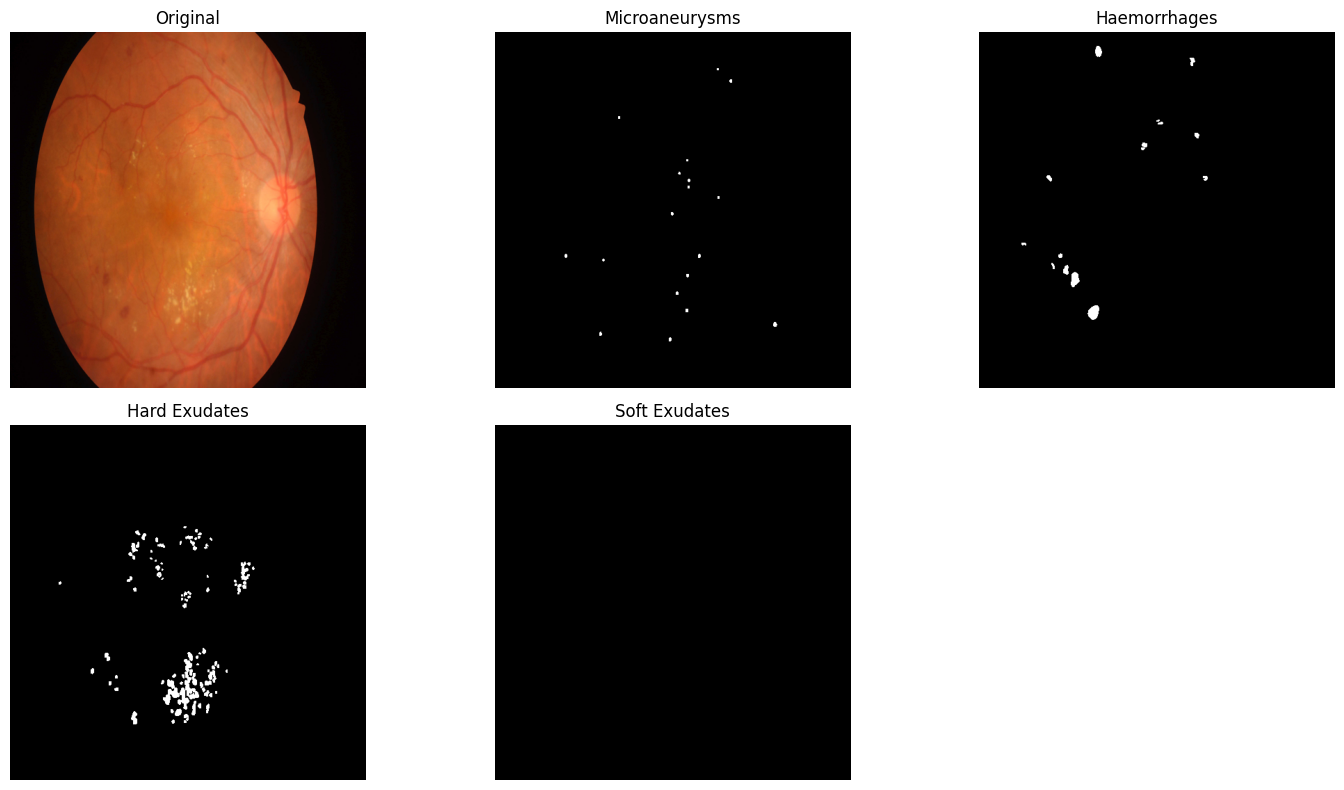

In [ ]:
image, masks, name = dataset[0]

plt.figure(figsize=(15, 8))

titles = [
    "Original",
    "Microaneurysms",
    "Haemorrhages",
    "Hard Exudates",
    "Soft Exudates"
]

plt.subplot(2, 3, 1)
plt.imshow(image.permute(1, 2, 0))
plt.title(titles[0])
plt.axis("off")

for i in range(4):
    plt.subplot(2, 3, i + 2)
    plt.imshow(masks[i], cmap="gray")
    plt.title(titles[i + 1])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 43
Validation images: 11


In [ ]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=4):
        super().__init__()

        self.enc1 = DoubleConv(3, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

seg_model = UNet(
    in_channels=3,
    out_channels=4
).to(device)

x = torch.randn(2, 3, 512, 512).to(device)

with torch.no_grad():
    y = seg_model(x)

print("Input shape :", x.shape)
print("Output shape:", y.shape)
print("Device:", device)

Input shape : torch.Size([2, 3, 512, 512])
Output shape: torch.Size([2, 4, 512, 512])
Device: cuda


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 11
Validation batches: 3


In [ ]:
import torch.nn.functional as F

def dice_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)

    intersection = (pred * target).sum(dim=(2, 3))
    union = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3))

    dice = (2 * intersection + smooth) / (union + smooth)

    return 1 - dice.mean()


def combined_loss(pred, target):
    bce = F.binary_cross_entropy_with_logits(pred, target)
    dice = dice_loss(pred, target)

    return bce + dice


optimizer = torch.optim.Adam(
    seg_model.parameters(),
    lr=1e-4
)

In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    seg_model.train()

    train_loss = 0.0

    for images, masks, _ in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = seg_model(images)

        loss = combined_loss(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # --------------------
    # Validation
    # --------------------
    seg_model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for images, masks, _ in val_loader:

            images = images.to(device)
            masks = masks.to(device)

            outputs = seg_model(images)

            loss = combined_loss(outputs, masks)

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/10] Train Loss: 1.6282 Val Loss: 1.6751
Epoch [2/10] Train Loss: 1.5537 Val Loss: 1.6462
Epoch [3/10] Train Loss: 1.5053 Val Loss: 1.5593
Epoch [4/10] Train Loss: 1.4811 Val Loss: 1.5018
Epoch [5/10] Train Loss: 1.4638 Val Loss: 1.4740
Epoch [6/10] Train Loss: 1.4522 Val Loss: 1.4524
Epoch [7/10] Train Loss: 1.4431 Val Loss: 1.6004
Epoch [8/10] Train Loss: 1.4354 Val Loss: 1.4351
Epoch [9/10] Train Loss: 1.4248 Val Loss: 1.4362
Epoch [10/10] Train Loss: 1.4170 Val Loss: 1.4231


In [ ]:
def calculate_metrics(pred, target, threshold=0.5):
    pred = torch.sigmoid(pred)
    pred = (pred > threshold).float()

    intersection = (pred * target).sum(dim=(2, 3))
    union = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3))

    dice = ((2 * intersection + 1e-6) /
            (union + 1e-6)).mean().item()

    intersection = (pred * target).sum(dim=(2, 3))
    total = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3)) - intersection

    iou = ((intersection + 1e-6) /
           (total + 1e-6)).mean().item()

    return dice, iou


seg_model.eval()

all_dice = []
all_iou = []

with torch.no_grad():

    for images, masks, _ in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = seg_model(images)

        dice, iou = calculate_metrics(outputs, masks)

        all_dice.append(dice)
        all_iou.append(iou)

print(f"Mean Dice Score: {sum(all_dice)/len(all_dice):.4f}")
print(f"Mean IoU Score:   {sum(all_iou)/len(all_iou):.4f}")

Mean Dice Score: 0.1464
Mean IoU Score:   0.1350


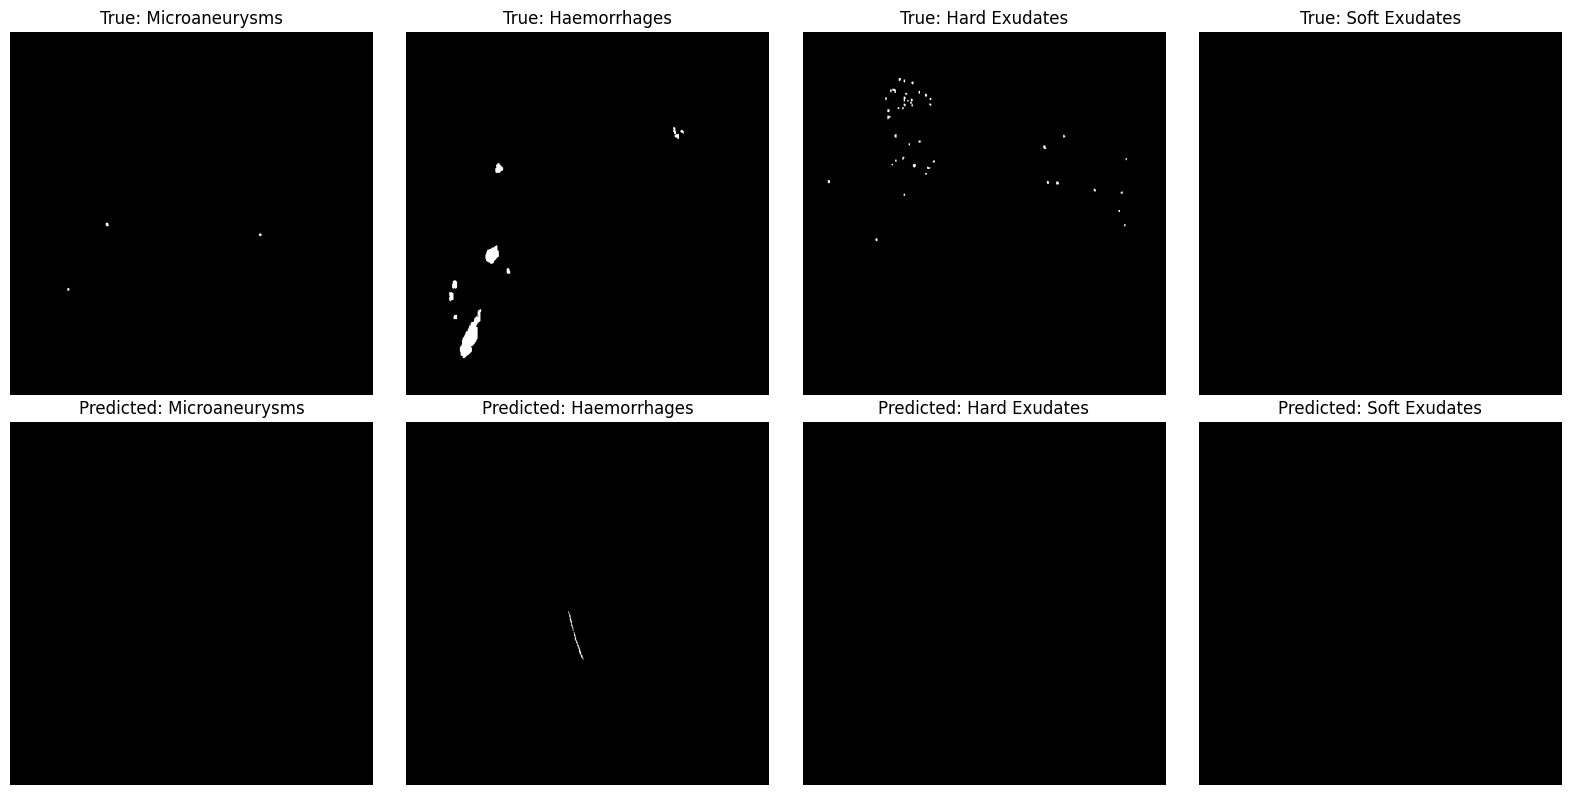

In [ ]:
seg_model.eval()

images, masks, names = next(iter(val_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = seg_model(images_gpu)
    predictions = torch.sigmoid(outputs).cpu()

image = images[0].permute(1, 2, 0).numpy()
true_masks = masks[0].numpy()
pred_masks = predictions[0].numpy()

titles = [
    "Microaneurysms",
    "Haemorrhages",
    "Hard Exudates",
    "Soft Exudates"
]

plt.figure(figsize=(16, 8))

for i in range(4):

    # Ground truth
    plt.subplot(2, 4, i + 1)
    plt.imshow(true_masks[i], cmap="gray")
    plt.title("True: " + titles[i])
    plt.axis("off")

    # Prediction
    plt.subplot(2, 4, i + 5)
    plt.imshow(pred_masks[i] > 0.5, cmap="gray")
    plt.title("Predicted: " + titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class IDRiDSegmentationDataset(Dataset):

    def __init__(self, image_dir, mask_dir, image_size=(512, 512)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

        self.images = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        self.lesion_info = {
            "MA": "1. Microaneurysms",
            "HE": "2. Haemorrhages",
            "EX": "3. Hard Exudates",
            "SE": "4. Soft Exudates"
        }

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_name = self.images[idx]
        image_id = os.path.splitext(image_name)[0]

        image = Image.open(
            os.path.join(self.image_dir, image_name)
        ).convert("RGB")

        image = image.resize(self.image_size)

        image = np.array(image).astype(np.float32) / 255.0
        image = torch.tensor(image).permute(2, 0, 1)

        masks = []
        valid = []

        for suffix, folder in self.lesion_info.items():

            mask_path = os.path.join(
                self.mask_dir,
                folder,
                image_id + "_" + suffix + ".tif"
            )

            if os.path.exists(mask_path):

                mask = Image.open(mask_path).convert("L")
                mask = mask.resize(self.image_size)

                mask = np.array(mask)
                mask = (mask > 0).astype(np.float32)

                masks.append(mask)
                valid.append(1.0)

            else:

                # Missing annotation
                masks.append(
                    np.zeros(self.image_size, dtype=np.float32)
                )

                valid.append(0.0)

        masks = torch.tensor(
            np.stack(masks),
            dtype=torch.float32
        )

        valid = torch.tensor(
            valid,
            dtype=torch.float32
        )

        return image, masks, valid, image_name

In [ ]:
dataset = IDRiDSegmentationDataset(
    image_dir=IMG_PATH,
    mask_dir=GT_PATH,
    image_size=(512, 512)
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

image, masks, valid, name = dataset[0]

print("Image:", image.shape)
print("Masks:", masks.shape)
print("Valid annotations:", valid)
print("Name:", name)

Image: torch.Size([3, 512, 512])
Masks: torch.Size([4, 512, 512])
Valid annotations: tensor([1., 1., 1., 0.])
Name: IDRiD_01.jpg


In [ ]:
def masked_combined_loss(pred, target, valid, smooth=1e-6):

    pred_prob = torch.sigmoid(pred)

    losses = []

    for c in range(4):

        # Skip missing annotations
        if valid[:, c].sum() == 0:
            continue

        p = pred_prob[:, c]
        t = target[:, c]

        v = valid[:, c].view(-1, 1, 1)

        bce = F.binary_cross_entropy(
            p,
            t,
            reduction="none"
        )

        bce = (bce * v).sum() / (v.sum() * p.shape[1] * p.shape[2] + smooth)

        intersection = (p * t * v).sum(dim=(1, 2))
        denominator = (
            p.sum(dim=(1, 2)) * v.squeeze(-1).squeeze(-1)
            + t.sum(dim=(1, 2)) * v.squeeze(-1).squeeze(-1)
        )

        dice = (
            (2 * intersection + smooth) /
            (denominator + smooth)
        )

        dice = 1 - dice.sum() / (v.sum() + smooth)

        losses.append(bce + dice)

    return sum(losses) / len(losses)

In [ ]:
seg_model = UNet(
    in_channels=3,
    out_channels=4
).to(device)

optimizer = torch.optim.Adam(
    seg_model.parameters(),
    lr=1e-4
)

print("Model reset and ready.")

Model reset and ready.


In [ ]:
num_epochs = 15

for epoch in range(num_epochs):

    seg_model.train()
    train_loss = 0.0

    for images, masks, valid, _ in train_loader:

        images = images.to(device)
        masks = masks.to(device)
        valid = valid.to(device)

        optimizer.zero_grad()

        outputs = seg_model(images)

        loss = masked_combined_loss(
            outputs,
            masks,
            valid
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    seg_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for images, masks, valid, _ in val_loader:

            images = images.to(device)
            masks = masks.to(device)
            valid = valid.to(device)

            outputs = seg_model(images)

            loss = masked_combined_loss(
                outputs,
                masks,
                valid
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/15] Train Loss: 1.3543 Val Loss: 1.2007
Epoch [2/15] Train Loss: 1.2747 Val Loss: 1.1625
Epoch [3/15] Train Loss: 1.2961 Val Loss: 1.0811
Epoch [4/15] Train Loss: 1.2777 Val Loss: 1.0217
Epoch [5/15] Train Loss: 1.4317 Val Loss: 1.0251
Epoch [6/15] Train Loss: 1.1961 Val Loss: 1.0051
Epoch [7/15] Train Loss: 1.2101 Val Loss: 1.0190
Epoch [8/15] Train Loss: 1.2496 Val Loss: 0.9763
Epoch [9/15] Train Loss: 1.1563 Val Loss: 0.9755
Epoch [10/15] Train Loss: 1.1541 Val Loss: 0.9661
Epoch [11/15] Train Loss: 1.1957 Val Loss: 0.9581
Epoch [12/15] Train Loss: 1.1623 Val Loss: 0.9425
Epoch [13/15] Train Loss: 1.3218 Val Loss: 0.9308
Epoch [14/15] Train Loss: 1.2027 Val Loss: 0.9707
Epoch [15/15] Train Loss: 1.1456 Val Loss: 0.9189


In [ ]:
def masked_metrics(pred, target, valid, threshold=0.5, smooth=1e-6):

    pred = (torch.sigmoid(pred) > threshold).float()

    dice_scores = []
    iou_scores = []

    for c in range(4):

        valid_idx = valid[:, c] == 1

        if valid_idx.sum() == 0:
            continue

        p = pred[valid_idx, c]
        t = target[valid_idx, c]

        intersection = (p * t).sum(dim=(1, 2))

        dice = (
            (2 * intersection + smooth) /
            (p.sum(dim=(1, 2)) +
             t.sum(dim=(1, 2)) +
             smooth)
        )

        union = (
            p.sum(dim=(1, 2)) +
            t.sum(dim=(1, 2)) -
            intersection
        )

        iou = (
            (intersection + smooth) /
            (union + smooth)
        )

        dice_scores.extend(dice.cpu().numpy())
        iou_scores.extend(iou.cpu().numpy())

    return np.mean(dice_scores), np.mean(iou_scores)


seg_model.eval()

all_dice = []
all_iou = []

with torch.no_grad():

    for images, masks, valid, _ in val_loader:

        images = images.to(device)
        masks = masks.to(device)
        valid = valid.to(device)

        outputs = seg_model(images)

        dice, iou = masked_metrics(
            outputs,
            masks,
            valid
        )

        all_dice.append(dice)
        all_iou.append(iou)

print(f"Corrected Mean Dice: {np.mean(all_dice):.4f}")
print(f"Corrected Mean IoU:  {np.mean(all_iou):.4f}")

Corrected Mean Dice: 0.0336
Corrected Mean IoU:  0.0192


In [ ]:
class_names = [
    "Microaneurysms",
    "Haemorrhages",
    "Hard Exudates",
    "Soft Exudates"
]

def classwise_metrics(model, loader):

    model.eval()

    dice_all = [[] for _ in range(4)]
    iou_all = [[] for _ in range(4)]

    with torch.no_grad():

        for images, masks, valid, _ in loader:

            images = images.to(device)
            masks = masks.to(device)
            valid = valid.to(device)

            outputs = torch.sigmoid(model(images))
            predictions = (outputs > 0.5).float()

            for c in range(4):

                valid_idx = valid[:, c] == 1

                if valid_idx.sum() == 0:
                    continue

                p = predictions[valid_idx, c]
                t = masks[valid_idx, c]

                intersection = (p * t).sum(dim=(1, 2))

                dice = (
                    (2 * intersection + 1e-6) /
                    (p.sum(dim=(1, 2)) +
                     t.sum(dim=(1, 2)) + 1e-6)
                )

                union = (
                    p.sum(dim=(1, 2)) +
                    t.sum(dim=(1, 2)) -
                    intersection
                )

                iou = (
                    (intersection + 1e-6) /
                    (union + 1e-6)
                )

                dice_all[c].extend(dice.cpu().numpy())
                iou_all[c].extend(iou.cpu().numpy())

    for c in range(4):

        if len(dice_all[c]) > 0:
            print(
                f"{class_names[c]:20s} "
                f"Dice: {np.mean(dice_all[c]):.4f} | "
                f"IoU: {np.mean(iou_all[c]):.4f}"
            )
        else:
            print(f"{class_names[c]:20s} No validation annotations")


classwise_metrics(seg_model, val_loader)

Microaneurysms       Dice: 0.0000 | IoU: 0.0000
Haemorrhages         Dice: 0.0026 | IoU: 0.0013
Hard Exudates        Dice: 0.0999 | IoU: 0.0576
Soft Exudates        Dice: 0.0000 | IoU: 0.0000


In [ ]:
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00


In [ ]:
import segmentation_models_pytorch as smp

seg_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=4,
    activation=None
).to(device)

print("Pretrained U-Net created.")
print("Device:", device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Pretrained U-Net created.
Device: cuda


In [ ]:
optimizer = torch.optim.AdamW(
    seg_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer ready.")

Optimizer ready.


In [ ]:
num_epochs = 15

for epoch in range(num_epochs):

    seg_model.train()
    train_loss = 0.0

    for images, masks, valid, _ in train_loader:

        images = images.to(device)
        masks = masks.to(device)
        valid = valid.to(device)

        optimizer.zero_grad()

        outputs = seg_model(images)

        loss = masked_combined_loss(
            outputs,
            masks,
            valid
        )

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    seg_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for images, masks, valid, _ in val_loader:

            images = images.to(device)
            masks = masks.to(device)
            valid = valid.to(device)

            outputs = seg_model(images)

            loss = masked_combined_loss(
                outputs,
                masks,
                valid
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/15] Train Loss: 1.5327 Val Loss: 1.2450
Epoch [2/15] Train Loss: 1.4803 Val Loss: 1.2123
Epoch [3/15] Train Loss: 1.3644 Val Loss: 1.1709
Epoch [4/15] Train Loss: 1.4213 Val Loss: 1.1393
Epoch [5/15] Train Loss: 1.3027 Val Loss: 1.1144
Epoch [6/15] Train Loss: 1.3100 Val Loss: 1.1374
Epoch [7/15] Train Loss: 1.2468 Val Loss: 1.1456
Epoch [8/15] Train Loss: 1.2886 Val Loss: 1.0783
Epoch [9/15] Train Loss: 1.1774 Val Loss: 1.2714
Epoch [10/15] Train Loss: 1.1479 Val Loss: 1.0560
Epoch [11/15] Train Loss: 1.1230 Val Loss: 0.9820
Epoch [12/15] Train Loss: 1.1854 Val Loss: 0.9580
Epoch [13/15] Train Loss: 1.1534 Val Loss: 1.0158
Epoch [14/15] Train Loss: 1.1769 Val Loss: 0.9692
Epoch [15/15] Train Loss: 1.0616 Val Loss: 0.9971


In [ ]:
classwise_metrics(seg_model, val_loader)

Microaneurysms       Dice: 0.0008 | IoU: 0.0004
Haemorrhages         Dice: 0.0332 | IoU: 0.0173
Hard Exudates        Dice: 0.0764 | IoU: 0.0433
Soft Exudates        Dice: 0.0058 | IoU: 0.0029


In [ ]:
# Cell 31 — Inspect prediction probabilities

seg_model.eval()

images, masks, valid, names = next(iter(val_loader))

images_gpu = images.to(device)

with torch.no_grad():
    outputs = torch.sigmoid(seg_model(images_gpu))

for c, name in enumerate([
    "Microaneurysms",
    "Haemorrhages",
    "Hard Exudates",
    "Soft Exudates"
]):
    probs = outputs[:, c]

    print(
        f"{name:20s} "
        f"min={probs.min().item():.4f} "
        f"max={probs.max().item():.4f} "
        f"mean={probs.mean().item():.4f}"
    )

Microaneurysms       min=0.0000 max=0.9848 mean=0.2217
Haemorrhages         min=0.0117 max=0.9884 mean=0.3917
Hard Exudates        min=0.0230 max=1.0000 mean=0.3583
Soft Exudates        min=0.0001 max=1.0000 mean=0.5297


In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

class_names = [
    "Microaneurysms",
    "Haemorrhages",
    "Hard Exudates",
    "Soft Exudates"
]

seg_model.eval()

for threshold in thresholds:

    class_dice = [[] for _ in range(4)]

    with torch.no_grad():

        for images, masks, valid, _ in val_loader:

            images = images.to(device)
            masks = masks.to(device)
            valid = valid.to(device)

            probs = torch.sigmoid(seg_model(images))
            preds = (probs > threshold).float()

            for c in range(4):

                valid_idx = valid[:, c] == 1

                if valid_idx.sum() == 0:
                    continue

                p = preds[valid_idx, c]
                t = masks[valid_idx, c]

                intersection = (p * t).sum(dim=(1, 2))

                dice = (
                    (2 * intersection + 1e-6) /
                    (p.sum(dim=(1, 2)) +
                     t.sum(dim=(1, 2)) + 1e-6)
                )

                class_dice[c].extend(
                    dice.cpu().numpy()
                )

    print(f"\nThreshold: {threshold}")

    for c in range(4):

        if class_dice[c]:
            print(
                f"{class_names[c]:20s}: "
                f"{np.mean(class_dice[c]):.4f}"
            )


Threshold: 0.1
Microaneurysms      : 0.0047
Haemorrhages        : 0.0122
Hard Exudates       : 0.0199
Soft Exudates       : 0.0051

Threshold: 0.2
Microaneurysms      : 0.0044
Haemorrhages        : 0.0123
Hard Exudates       : 0.0199
Soft Exudates       : 0.0065

Threshold: 0.3
Microaneurysms      : 0.0056
Haemorrhages        : 0.0128
Hard Exudates       : 0.0216
Soft Exudates       : 0.0071

Threshold: 0.4
Microaneurysms      : 0.0065
Haemorrhages        : 0.0207
Hard Exudates       : 0.0429
Soft Exudates       : 0.0071

Threshold: 0.5
Microaneurysms      : 0.0008
Haemorrhages        : 0.0332
Hard Exudates       : 0.0764
Soft Exudates       : 0.0058

Threshold: 0.6
Microaneurysms      : 0.0000
Haemorrhages        : 0.0235
Hard Exudates       : 0.0111
Soft Exudates       : 0.0055

Threshold: 0.7
Microaneurysms      : 0.0000
Haemorrhages        : 0.0000
Hard Exudates       : 0.0007
Soft Exudates       : 0.0068


In [ ]:
torch.save(
    seg_model.state_dict(),
    "/content/drive/MyDrive/SIH26038_IDRiD_UNet_experiment.pth"
)

print("Segmentation experiment model saved.")

Segmentation experiment model saved.


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/SIH26038_final_model.pth"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>